In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from scipy.integrate import quad

plt.style.use(['science'])

# Constants
c = 299792.458   # km / s
H0 = 67       # km / s / Mpc
fv0 = 0.695

In [ ]:
def H_bar_0(fv0, H_0):
    return 2 * (2 + fv0) * H_0 / (4 *fv0**2 + fv0 + 4)


def b(fv0, H_0):
    output = 2 * (1 - fv0) * (2 + fv0) / (9 * fv0 * H_bar_0(fv0, H_0))
    return output


def F(t, fv0, H_0):
    term1 = 2 * t ** (1/3)
    term2 = b(fv0, H_0)**(1/3) / 6 * np.log( (t**(1/3) + b(fv0, H_0)**(1/3))**2 / (t **(2/3) - b(fv0, H_0)**(1/3) * t**(1/3) + b(fv0, H_0)**(2/3)) )
    term3 = b(fv0, H_0)**(1/3) / np.sqrt(3) * np.arctan( (2 * t**(1/3) - b(fv0, H_0)**(1/3)) / (np.sqrt(3) * b(fv0, H_0)**(1/3)) )
    return term1 + term2 + term3


def angular_diameter_distance(t, t0, fv0, H_0):
    return c * t ** (2 / 3) * (F(t0, fv0, H_0) - F(t, fv0, H_0))

def z_of_t(t, fv0, H_0):
    return 2**(4/3) * t ** (1/3) * (t + b(fv0, H_0)) / (fv0 **(1/3) * H_bar_0(fv0, H_0)* t * (2*t+3*b(fv0, H_0))**(4/3)) -1

In [70]:
t_present = (2 + fv0) / (3*H_bar_0(fv0, H0))

print("Present time t0:", t_present)
z_of_t(t_present,fv0,H0)

Present time t0: 0.016485323383084574


2.220446049250313e-16

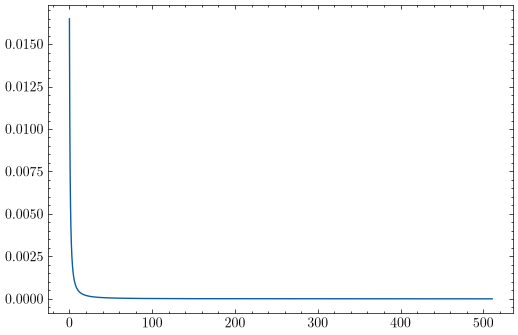

In [73]:
tt = np.geomspace(1e-4 * t_present, t_present, 1000)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(z_of_t(tt, fv0, H0), tt)
# ax.vlines(t_present, 0, 120, color='r', linestyle='--', label='Present time')

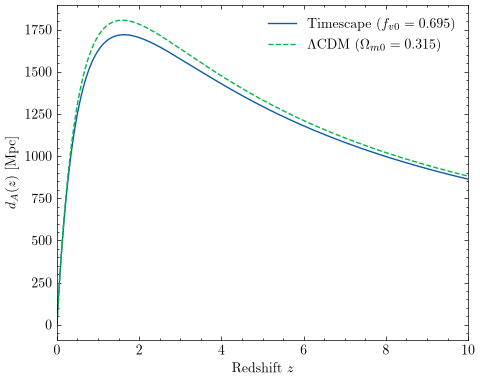

In [74]:

# 1. Sample volume-average time t from early universe up to t_present
# Using logspace gives smooth resolution across both low z and high z (up to z ~ 120)
tt = np.geomspace(1e-4 * t_present, t_present, 1000)

z_ts = z_of_t(tt, fv0, H0)
dA_ts = angular_diameter_distance(tt, t_present, fv0, H0)  # In Mpc

# 2. Compute Flat LCDM angular diameter distance for comparison (Omega_m0 = 0.315)
Omega_m0 = 0.315
def dA_lcdm(z_array, H0, Omega_m0):
    dA_list = []
    for z in z_array:
        integrand = lambda zp: 1.0 / np.sqrt(Omega_m0 * (1 + zp)**3 + (1 - Omega_m0))
        dc, _ = quad(integrand, 0, z)
        dA_list.append((c / H0) * dc / (1 + z))
    return np.array(dA_list)

dA_lcdm_vals = dA_lcdm(z_ts, H0, Omega_m0)

# 3. Plot d_A(z) for z in [0, 10] and the full range up to z ~ 120
fig, ax1 = plt.subplots(figsize=(5, 4))

# Left panel: Low-to-intermediate redshift (shows the turnaround peak at z ~ 1.6)
ax1.plot(z_ts, dA_ts, label=f'Timescape ($f_{{v0}}={fv0}$)')
ax1.plot(z_ts, dA_lcdm_vals, '--', label=f'$\\Lambda$CDM ($\\Omega_{{m0}}={Omega_m0}$)')
ax1.set_xlim(0, 10)
ax1.set_xlabel('Redshift $z$')
ax1.set_ylabel('$d_A(z)$ [Mpc]')
ax1.legend()

plt.tight_layout()
plt.show()

In [72]:
t_near = 0.9999 * t_present
print("Effective H0 at z->0:", c * z_of_t(t_near, fv0, H0) / angular_diameter_distance(t_near, t_present, fv0, H0))

Effective H0 at z->0: 67.00762713653093
